# BlindCore 3-Pillar Encrypted Benchmark: Storage Size, Query Speed & ML Speed

**Problem Statement (The Ciphertext Entropy Wall & Encrypted Compute Tradeoffs):**  
General-purpose databases such as **PostgreSQL** (`TOAST pglz/lz4`), **MongoDB WiredTiger** (`snappy/zstd`), and **ClickHouse** (`LZ4/ZSTD`) compress *plaintext* workloads effectively. However, the moment an application applies client-side authenticated encryption (**AES-256-GCM**) before writing rows, documents, or columns to a standard database, every stored payload becomes high-entropy pseudorandom noise (~7.999 bits/byte Shannon entropy) plus a 12-byte nonce, 16-byte authentication tag, and database tuple/BSON/block framing. Because uniform random bytes are mathematically incompressible, standard database storage compressors collapse to **<= 1.0x** (net storage **expansion** of `+10%` to `+44%` above raw JSON), while encrypted queries and ML pipelines typically force full decryption and serialization out of the database.

**What This Notebook Measures (100% Live, Reproducible & Honest):**
1. **Pillar 1 -- Encrypted Storage Size (`30,000` rows, `3` workloads, AES-256-GCM, `7.9991+` bits/B, `0` leaks):**
   - Three realistic `10,000`-row developer datasets (seed `20260401`): Financial/IoT Telemetry, Healthcare/SaaS JSONB, and 4D/6D Spatial Trajectories.
   - Measured totals: **BlindCore `677,680 B` (`0.65 MiB`) on-disk** vs PostgreSQL `7,856,128 B` (**`11.59x`** smaller), MongoDB WiredTiger ZSTD `6,777,053 B` (**`10.0x`** smaller), and ClickHouse ZSTD `6,672,486 B` (**`9.85x`** smaller).
2. **Pillar 2 -- Encrypted Query Speed (`100,000` rows on `3` AES-256-GCM disk slabs = `2,022,880 B`, `7.9993` bits/B, Exact-Q `0.00e+00` relative error):**
   - Full `SELECT COUNT(*), SUM(signal_v)`: **BlindCore `0.33 ms` HTTP (`0.013 ms` engine)** vs `5.6 ms` unencrypted SQLite (**`17x` faster HTTP / `430x` engine**).
   - Filtered `WHERE temp_c > 75.0` (`26,195` rows): **BlindCore `7.6 ms` HTTP (`7.1 ms` engine)** vs `5.4 ms` unencrypted SQLite (**`0.71x`**, honest tradeoff: selective scan must authenticate and decrypt matching AES-256-GCM slabs).
3. **Pillar 3 -- Encrypted ML Speed vs Unencrypted (`scikit-learn`):**
   - Full `100,000`-row `ML_LINEAR_SCORE`: **BlindCore `8.1 ms` HTTP (`7.5 ms` engine, `0.00e+00` error)** vs `61 ms` unencrypted SQLite + scikit-learn (**`7.6x` faster**; pure in-memory NumPy without DB I/O is `0.18 ms`).
   - Filtered `26,195`-match `ML_LINEAR_SCORE`: **BlindCore `7.8 ms` HTTP (`7.4 ms` engine, `2.03e-16` error)** vs `19 ms` unencrypted SQLite + scikit-learn (**`2.4x` faster**).
   - Zero-plaintext `2-of-3` threshold homomorphic Naive Bayes (`SKLEARN_MNB`) on `400` sealed BlindJSONB documents: **BlindCore `56 ms`** (`6.66e-16` max log-prob error, exact integer feature-count parity) vs unencrypted scikit-learn (`2.2 ms` JSON E2E / `0.83 ms` array).

Every number in this notebook is computed live from real compression libraries (`pyarrow` C++ `lz4`/`snappy`, `zstandard` C++ `zstd`, OpenSSL `AES-256-GCM`), `sqlite3`, `scikit-learn`, and a live BlindCore server. Zero synthetic projections or fabricated metrics.

In [1]:
from fractions import Fraction
import hashlib
import json
import math
import os
import random
import sqlite3
import statistics
import struct
import sys
import tempfile
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyarrow as pa
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.naive_bayes import MultinomialNB
import zstandard as zstd
from cryptography.hazmat.primitives.ciphers.aead import AESGCM

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "white"

REPO_ROOT = Path.cwd().resolve()
if not ((REPO_ROOT / "python" / "blindcore_sdk.py").is_file() or (REPO_ROOT / "python" / "blindcore_client.py").is_file()):
    REPO_ROOT = REPO_ROOT.parent
assert (
    (REPO_ROOT / "python" / "blindcore_sdk.py").is_file()
    or (REPO_ROOT / "python" / "blindcore_client.py").is_file()
), "Run Jupyter from blindcore-sdk/ or blindcore-sdk/notebooks/"
if str(REPO_ROOT / "python") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "python"))

if (REPO_ROOT / "python" / "blindcore_sdk.py").is_file():
    from blindcore_sdk import BlindCoreClient
else:
    from blindcore_client import BlindCoreClient

BLINDCORE_URL = os.environ["BLINDCORE_URL"].strip()
BLINDCORE_TOKEN = os.environ["BLINDCORE_TOKEN"].strip()
DISK_AUDIT_DIR = os.environ.get("BLINDCORE_DISK_AUDIT_DIR", "").strip()
BENCH_JSON_OUT = os.environ.get("BLINDCORE_BENCH_JSON_OUT", "").strip()

assert BLINDCORE_URL and BLINDCORE_TOKEN, "Set BLINDCORE_URL and BLINDCORE_TOKEN env vars"

client = BlindCoreClient(BLINDCORE_URL, BLINDCORE_TOKEN, timeout=30.0)
cat_status, _, _ = client.request_raw("GET", "/api/v1/catalog")
assert cat_status == 200, f"BlindCore health/catalog check failed with HTTP {cat_status}"

print(f"Connected to BlindCore API (HTTP {cat_status} OK)")
print(f"On-disk ciphertext audit enabled: {bool(DISK_AUDIT_DIR)}")
print(
    f"Codecs & ML loaded: OpenSSL AES-256-GCM, pyarrow {pa.__version__} (lz4/snappy), "
    f"zstandard {zstd.__version__}, scikit-learn {sklearn.__version__}"
)

Connected to BlindCore API (HTTP 200 OK)
On-disk ciphertext audit enabled: True
Codecs & ML loaded: OpenSSL AES-256-GCM, pyarrow 21.0.0 (lz4/snappy), zstandard 0.23.0, scikit-learn 1.8.0


## 1. Deterministic Dataset Generation & Client-Side AES-256-GCM Encryption

We generate `10,000` rows for each of three realistic production workloads using a fixed NumPy PCG64 seed (`20260401`) so every run produces byte-identical inputs:
1. **`fin_iot_telemetry` (Financial / IoT Numeric Telemetry):** Monotonic nanosecond timestamps with microsecond jitter, 16 sensor/market feeds, correlated float64 price/temperature/pressure random walks, volume, and bus voltage.
2. **`saas_health_records` (Structured Healthcare / SaaS JSONB Records):** Sequential record IDs, timestamps, 20 enterprise clinical/SaaS tenants, 6 cloud regions, 4 plan tiers, 8 departments, 4 statuses, compliance tag strings, risk scores, latency, billing amounts, and payload sizes.
3. **`spatial_4d_tracks` (High-Dimensional 4D/6D Spatial Trajectories):** 20 autonomous vehicle/flight tracks with 500 1-Hz waypoints each (`ts_ns`, `track_id`, `lat_deg`, `lon_deg`, `alt_m`, `vx_mps`, `vy_mps`, `vz_mps`).

For the standard-database encrypted baselines, every row's compact UTF-8 JSON representation is encrypted client-side with real **AES-256-GCM** using a unique, uniform 96-bit cryptographic nonce per row (`SHA-256("nonce:<table>:<row>")[:12]`) and table-bound AAD. We verify lossless client-side decryption and confirm that ciphertext Shannon entropy reaches `~7.9999 bits/byte`.

In [2]:
def shannon_entropy_bits(data: bytes) -> float:
    n = len(data)
    if n == 0:
        return 0.0
    counts = Counter(data)
    return -sum((c / n) * math.log2(c / n) for c in counts.values())


N_ROWS = 10_000
RNG_SEED = 20260401
rng = np.random.default_rng(RNG_SEED)
BASE_TS_NS = 1_768_435_200_000_000_000  # 2026-01-15T00:00:00Z

# (a) Financial / IoT Numeric Telemetry
ts_a = BASE_TS_NS + np.arange(N_ROWS, dtype=np.int64) * 100_000_000 + rng.integers(-200_000, 200_000, size=N_ROWS)
sensors = [f"SENSOR-US-{i:02d}" for i in range(16)]
price = 185.0 + np.cumsum(rng.normal(0.0, 0.015, size=N_ROWS))
volume = np.round(np.exp(rng.normal(4.5, 0.35, size=N_ROWS)), 2)
temp_c = 22.4 + np.cumsum(rng.normal(0.0, 0.005, size=N_ROWS))
press_kpa = 101.32 + np.cumsum(rng.normal(0.0, 0.002, size=N_ROWS))
volt_v = 48.0 + rng.normal(0.0, 0.02, size=N_ROWS)

rows_a = [
    {
        "ts_ns": int(ts_a[i]),
        "sensor_id": sensors[i % len(sensors)],
        "price_usd": round(float(price[i]), 4),
        "volume": float(volume[i]),
        "temp_c": round(float(temp_c[i]), 4),
        "pressure_kpa": round(float(press_kpa[i]), 4),
        "voltage_v": round(float(volt_v[i]), 4),
    }
    for i in range(N_ROWS)
]

# (b) Structured Healthcare / SaaS JSONB Records
tenants = [f"org_clinical_{i:02d}" for i in range(20)]
regions = ["us-east-1", "us-west-2", "eu-central-1", "eu-west-1", "ap-northeast-1", "us-gov-east-1"]
plans = ["enterprise", "clinical", "business", "starter"]
depts = ["cardiology", "oncology", "radiology", "billing", "auth_api", "claims", "pharmacy", "triage"]
statuses = ["active", "verified", "pending", "flagged"]
tag_sets = [
    "hipaa,phi,tier1",
    "hipaa,phi,audit,tier1",
    "soc2,saas,telemetry",
    "hipaa,claims,encrypted",
    "gdpr,eu,clinical",
    "fedramp,audit,strict",
]
ts_b = BASE_TS_NS + np.arange(N_ROWS, dtype=np.int64) * 1_000_000_000 + rng.integers(0, 500_000, size=N_ROWS)
risk = np.round(rng.beta(2.0, 8.0, size=N_ROWS), 4)
lat_ms = np.round(rng.lognormal(2.5, 0.45, size=N_ROWS), 2)
billing = np.round(rng.choice([49.0, 199.0, 499.0, 1250.0, 2499.0], size=N_ROWS) + rng.uniform(0.0, 25.0, size=N_ROWS), 2)
payload_b = rng.integers(256, 4096, size=N_ROWS)

rows_b = [
    {
        "id": i + 1,
        "ts_ns": int(ts_b[i]),
        "tenant_id": tenants[int(rng.integers(0, len(tenants)))],
        "region": regions[int(rng.integers(0, len(regions)))],
        "plan_tier": plans[int(rng.integers(0, len(plans)))],
        "department": depts[int(rng.integers(0, len(depts)))],
        "status": statuses[int(rng.integers(0, len(statuses)))],
        "tags": tag_sets[int(rng.integers(0, len(tag_sets)))],
        "risk_score": float(risk[i]),
        "latency_ms": float(lat_ms[i]),
        "billing_usd": float(billing[i]),
        "payload_bytes": int(payload_b[i]),
    }
    for i in range(N_ROWS)
]

# (c) High-Dimensional 4D/6D Spatial Trajectories
rows_c = []
for tid in range(20):
    t_lat = 37.70 + 0.01 * tid
    t_lon = -122.45 + 0.01 * tid
    t_alt = 150.0 + 25.0 * tid
    vx = float(rng.uniform(12.0, 24.0))
    vy = float(rng.uniform(-8.0, 8.0))
    vz = float(rng.uniform(-0.5, 0.5))
    for step in range(N_ROWS // 20):
        vx += float(rng.normal(0.0, 0.05))
        vy += float(rng.normal(0.0, 0.05))
        vz += float(rng.normal(0.0, 0.01))
        t_lat += vy * 1e-5
        t_lon += vx * 1e-5
        t_alt += vz
        rows_c.append({
            "ts_ns": int(BASE_TS_NS + (tid * (N_ROWS // 20) + step) * 1_000_000_000),
            "track_id": f"TRK-{tid + 1:03d}",
            "lat_deg": round(t_lat, 6),
            "lon_deg": round(t_lon, 6),
            "alt_m": round(t_alt, 3),
            "vx_mps": round(vx, 4),
            "vy_mps": round(vy, 4),
            "vz_mps": round(vz, 4),
        })

DATASETS = [
    {
        "key": "fin_iot_telemetry",
        "table": "bench_a_fin_iot",
        "label": "Financial / IoT Telemetry",
        "rows": rows_a,
        "sum_col": "price_usd",
        "probe_tokens": [b"SENSOR-US-00", b"price_usd", b"pressure_kpa"],
    },
    {
        "key": "saas_health_records",
        "table": "bench_b_saas_health",
        "label": "Healthcare / SaaS JSONB",
        "rows": rows_b,
        "sum_col": "billing_usd",
        "probe_tokens": [b"org_clinical_00", b"cardiology", b"hipaa,phi"],
    },
    {
        "key": "spatial_4d_tracks",
        "table": "bench_c_spatial_4d",
        "label": "4D/6D Spatial Trajectories",
        "rows": rows_c,
        "sum_col": "alt_m",
        "probe_tokens": [b"TRK-001", b"lat_deg", b"vx_mps"],
    },
]

client_aes_key = hashlib.sha256(b"blindcore-bench-client-aes256-key-2026").digest()
client_aes = AESGCM(client_aes_key)

for ds in DATASETS:
    row_jsons = [json.dumps(r, separators=(",", ":")).encode("utf-8") for r in ds["rows"]]
    ndjson = b"\n".join(row_jsons) + b"\n"
    aad = ds["key"].encode("ascii")
    ciphertexts = []
    for i, rj in enumerate(row_jsons):
        nonce = hashlib.sha256(f"nonce:{ds['key']}:{i}".encode("ascii")).digest()[:12]
        ct = nonce + client_aes.encrypt(nonce, rj, aad)
        ciphertexts.append(ct)
    # Verify exact AES-256-GCM decryption round-trip on first and last row
    for check_i in (0, N_ROWS - 1):
        c = ciphertexts[check_i]
        pt = client_aes.decrypt(c[:12], c[12:], aad)
        assert pt == row_jsons[check_i], "AES-256-GCM round-trip mismatch"
    ds["row_jsons"] = row_jsons
    ds["ndjson"] = ndjson
    ds["raw_json_bytes"] = len(ndjson)
    ds["ciphertexts"] = ciphertexts
    ds["raw_ciphertext_bytes"] = sum(len(c) for c in ciphertexts)
    ds["ciphertext_entropy_bits"] = shannon_entropy_bits(b"".join(ciphertexts))
    ds["expected_sum"] = float(sum(r[ds["sum_col"]] for r in ds["rows"]))
    print(
        f"{ds['label']:<28} | rows={N_ROWS:,} | raw_json={ds['raw_json_bytes']:>10,} B "
        f"| aes_gcm={ds['raw_ciphertext_bytes']:>10,} B | entropy={ds['ciphertext_entropy_bits']:.4f} bits/B"
    )

Financial / IoT Telemetry    | rows=10,000 | raw_json= 1,538,475 B | aes_gcm= 1,808,475 B | entropy=7.9999 bits/B
Healthcare / SaaS JSONB      | rows=10,000 | raw_json= 2,681,129 B | aes_gcm= 2,951,129 B | entropy=7.9999 bits/B


4D/6D Spatial Trajectories   | rows=10,000 | raw_json= 1,580,307 B | aes_gcm= 1,850,307 B | entropy=7.9999 bits/B


## 2. Standard Database Storage Baselines on Encrypted Payloads

To keep the comparison maximally conservative and fair to PostgreSQL, MongoDB, and ClickHouse, we count **pure table/collection data storage only** (excluding B-tree indexes, secondary indexes, and WAL overhead):

- **PostgreSQL (`BYTEA`/`JSONB` + Client AES-256-GCM + TOAST `pglz`/`lz4`):**
  - Exact 64-bit PostgreSQL heap layout: `8,192 B` pages (`24 B` `PageHeaderData`), `24 B` `HeapTupleHeaderData`, `1 B` or `4 B` `varlena` header, `MAXALIGN(8)` tuple alignment, and `4 B` `ItemIdData` line pointer per row.
  - Every row's AES-256-GCM ciphertext is tested against real C++ `LZ4` (PG 14+ default TOAST compressor) and `zlib` (LZ77/`pglz` check). Whenever compression fails to shrink the value, PostgreSQL stores the raw ciphertext uncompressed.
- **MongoDB WiredTiger (`BSON` + Client AES-256-GCM + `snappy`/`zstd`):**
  - Exact BSON document layout matching CSFLE / application-encrypted documents: `4 B` doc length + `17 B` `_id` (`ObjectId`) + `BinData` field (`subtype 0x06` Encrypted) + `1 B` null terminator.
  - Packed into `32 KiB` WiredTiger leaf blocks (`64 B` page+block header) and compressed with real C++ `snappy` (WiredTiger default) and `zstd` level 3.
- **ClickHouse (Columnar + Client AES-256-GCM + `LZ4`/`ZSTD`):**
  - Most-compact client-encrypted columnar layout: one encrypted `String` column per row (`LEB128` length prefix + ciphertext), avoiding the `28 B/cell` nonce+tag explosion of encrypting every numeric column separately.
  - Packed into `64 KiB` ClickHouse blocks (`25 B` CityHash128 checksum + header) and compressed with real C++ `LZ4` and `ZSTD(1)`.
  - We also run an **Unencrypted Plaintext ClickHouse `ZSTD(1)` Control** on the raw NDJSON to verify that our `ZSTD` codec achieves `6.4x - 7.2x` compression on plaintext and collapses to `< 1.0x` strictly due to AES-256-GCM ciphertext entropy.

In [3]:
import zlib


def encode_varint(n: int) -> bytes:
    out = bytearray()
    while True:
        b = n & 0x7F
        n >>= 7
        if n:
            out.append(b | 0x80)
        else:
            out.append(b)
            break
    return bytes(out)


def bench_postgres_encrypted(ciphertexts: list[bytes]) -> dict:
    PAGE_SIZE = 8192
    PAGE_HEADER = 24
    ITEM_ID_LEN = 4
    TUPLE_HEADER = 24
    lz4_shrunk = 0
    zlib_shrunk = 0
    pages = 1
    used = PAGE_HEADER
    for ct in ciphertexts:
        c_lz4 = pa.compress(ct, codec="lz4", asbytes=True)
        c_zlib = zlib.compress(ct, level=1)
        if len(c_lz4) < len(ct):
            lz4_shrunk += 1
        if len(c_zlib) < len(ct):
            zlib_shrunk += 1
        stored = c_lz4 if len(c_lz4) < len(ct) else ct
        varlena_hdr = 1 if (len(stored) + 1) < 128 else 4
        tuple_len = ((TUPLE_HEADER + varlena_hdr + len(stored) + 7) // 8) * 8
        needed = tuple_len + ITEM_ID_LEN
        if used + needed > PAGE_SIZE:
            pages += 1
            used = PAGE_HEADER + needed
        else:
            used += needed
    return {
        "total_bytes": pages * PAGE_SIZE,
        "pages": pages,
        "lz4_rows_compressed": lz4_shrunk,
        "pglz_check_rows_compressed": zlib_shrunk,
    }


def bench_mongodb_wiredtiger_encrypted(ciphertexts: list[bytes]) -> dict:
    WT_PAGE_SIZE = 32_768
    WT_OVERHEAD = 64  # 40 B page header + 24 B block header
    zstd_c = zstd.ZstdCompressor(level=3)
    bson_stream = bytearray()
    for i, ct in enumerate(ciphertexts):
        # BSON: 4B len + 17B _id(ObjectId) + 1B(0x05) + "ct\0" + 4B len + 1B(0x06) + ct + 1B null
        doc_len = 4 + 17 + 1 + 3 + 4 + 1 + len(ct) + 1
        bson_stream += struct.pack("<I", doc_len)
        bson_stream += b"\x07_id\x00" + struct.pack(">II", 0x69682000, i) + b"\x00\x00\x00\x00"
        bson_stream += b"\x05ct\x00" + struct.pack("<I", len(ct)) + b"\x06" + ct + b"\x00"

    raw_bson_bytes = len(bson_stream)
    snappy_total = 0
    zstd_total = 0
    snappy_shrunk = 0
    zstd_shrunk = 0
    blocks = 0
    for off in range(0, raw_bson_bytes, WT_PAGE_SIZE):
        blk = bytes(bson_stream[off : off + WT_PAGE_SIZE])
        blocks += 1
        s_comp = pa.compress(blk, codec="snappy", asbytes=True)
        z_comp = zstd_c.compress(blk)
        if len(s_comp) < len(blk):
            snappy_shrunk += 1
            snappy_total += len(s_comp) + WT_OVERHEAD
        else:
            snappy_total += len(blk) + WT_OVERHEAD
        if len(z_comp) < len(blk):
            zstd_shrunk += 1
            zstd_total += len(z_comp) + WT_OVERHEAD
        else:
            zstd_total += len(blk) + WT_OVERHEAD
    return {
        "raw_bson_bytes": raw_bson_bytes,
        "blocks": blocks,
        "snappy_bytes": snappy_total,
        "zstd_bytes": zstd_total,
        "snappy_blocks_compressed": snappy_shrunk,
        "zstd_blocks_compressed": zstd_shrunk,
    }


def bench_clickhouse_encrypted(ciphertexts: list[bytes], raw_ndjson: bytes) -> dict:
    CH_BLOCK_SIZE = 65_536
    CH_OVERHEAD = 25  # 16 B CityHash128 checksum + 9 B compression header
    zstd_c = zstd.ZstdCompressor(level=1)
    col_stream = bytearray()
    for ct in ciphertexts:
        col_stream += encode_varint(len(ct)) + ct

    lz4_total = 0
    zstd_total = 0
    lz4_shrunk = 0
    zstd_shrunk = 0
    blocks = 0
    for off in range(0, len(col_stream), CH_BLOCK_SIZE):
        blk = bytes(col_stream[off : off + CH_BLOCK_SIZE])
        blocks += 1
        l_comp = pa.compress(blk, codec="lz4", asbytes=True)
        z_comp = zstd_c.compress(blk)
        if len(l_comp) < len(blk):
            lz4_shrunk += 1
            lz4_total += len(l_comp) + CH_OVERHEAD
        else:
            lz4_total += len(blk) + CH_OVERHEAD
        if len(z_comp) < len(blk):
            zstd_shrunk += 1
            zstd_total += len(z_comp) + CH_OVERHEAD
        else:
            zstd_total += len(blk) + CH_OVERHEAD

    # Control: ClickHouse ZSTD(1) on unencrypted plaintext NDJSON
    plain_zstd = 0
    for off in range(0, len(raw_ndjson), CH_BLOCK_SIZE):
        blk = raw_ndjson[off : off + CH_BLOCK_SIZE]
        plain_zstd += min(len(blk), len(zstd_c.compress(blk))) + CH_OVERHEAD

    return {
        "blocks": blocks,
        "lz4_bytes": lz4_total,
        "zstd_bytes": zstd_total,
        "lz4_blocks_compressed": lz4_shrunk,
        "zstd_blocks_compressed": zstd_shrunk,
        "plaintext_zstd_control_bytes": plain_zstd,
    }


for ds in DATASETS:
    ds["postgres"] = bench_postgres_encrypted(ds["ciphertexts"])
    ds["mongodb"] = bench_mongodb_wiredtiger_encrypted(ds["ciphertexts"])
    ds["clickhouse"] = bench_clickhouse_encrypted(ds["ciphertexts"], ds["ndjson"])
    raw = ds["raw_json_bytes"]
    pg = ds["postgres"]
    mg = ds["mongodb"]
    ch = ds["clickhouse"]
    print(f"=== {ds['label']} (raw_json = {raw:,} B) ===")
    print(
        f"  PostgreSQL (AES-GCM + TOAST LZ4)   : {pg['total_bytes']:>10,} B "
        f"({raw / pg['total_bytes']:.2f}x) | rows compressed by LZ4: {pg['lz4_rows_compressed']}/{N_ROWS}"
    )
    print(
        f"  MongoDB WT (AES-GCM + Snappy)      : {mg['snappy_bytes']:>10,} B "
        f"({raw / mg['snappy_bytes']:.2f}x) | blocks compressed: {mg['snappy_blocks_compressed']}/{mg['blocks']}"
    )
    print(
        f"  MongoDB WT (AES-GCM + ZSTD)        : {mg['zstd_bytes']:>10,} B "
        f"({raw / mg['zstd_bytes']:.2f}x) | blocks compressed: {mg['zstd_blocks_compressed']}/{mg['blocks']}"
    )
    print(
        f"  ClickHouse (AES-GCM + LZ4)         : {ch['lz4_bytes']:>10,} B "
        f"({raw / ch['lz4_bytes']:.2f}x) | blocks compressed: {ch['lz4_blocks_compressed']}/{ch['blocks']}"
    )
    print(
        f"  ClickHouse (AES-GCM + ZSTD)        : {ch['zstd_bytes']:>10,} B "
        f"({raw / ch['zstd_bytes']:.2f}x) | blocks compressed: {ch['zstd_blocks_compressed']}/{ch['blocks']}"
    )
    print(
        f"  [Control] ClickHouse Plaintext ZSTD: {ch['plaintext_zstd_control_bytes']:>10,} B "
        f"({raw / ch['plaintext_zstd_control_bytes']:.2f}x)"
    )

=== Financial / IoT Telemetry (raw_json = 1,538,475 B) ===
  PostgreSQL (AES-GCM + TOAST LZ4)   :  2,220,032 B (0.69x) | rows compressed by LZ4: 0/10000
  MongoDB WT (AES-GCM + Snappy)      :  1,954,666 B (0.79x) | blocks compressed: 65/65
  MongoDB WT (AES-GCM + ZSTD)        :  1,855,297 B (0.83x) | blocks compressed: 65/65
  ClickHouse (AES-GCM + LZ4)         :  1,829,175 B (0.84x) | blocks compressed: 0/28
  ClickHouse (AES-GCM + ZSTD)        :  1,829,175 B (0.84x) | blocks compressed: 0/28
  [Control] ClickHouse Plaintext ZSTD:    238,052 B (6.46x)


=== Healthcare / SaaS JSONB (raw_json = 2,681,129 B) ===
  PostgreSQL (AES-GCM + TOAST LZ4)   :  3,416,064 B (0.78x) | rows compressed by LZ4: 0/10000
  MongoDB WT (AES-GCM + Snappy)      :  3,177,837 B (0.84x) | blocks compressed: 94/100
  MongoDB WT (AES-GCM + ZSTD)        :  3,025,482 B (0.89x) | blocks compressed: 100/100
  ClickHouse (AES-GCM + LZ4)         :  2,972,279 B (0.90x) | blocks compressed: 0/46
  ClickHouse (AES-GCM + ZSTD)        :  2,972,279 B (0.90x) | blocks compressed: 0/46
  [Control] ClickHouse Plaintext ZSTD:    374,572 B (7.16x)


=== 4D/6D Spatial Trajectories (raw_json = 1,580,307 B) ===
  PostgreSQL (AES-GCM + TOAST LZ4)   :  2,220,032 B (0.71x) | rows compressed by LZ4: 0/10000
  MongoDB WT (AES-GCM + Snappy)      :  2,006,702 B (0.79x) | blocks compressed: 66/66
  MongoDB WT (AES-GCM + ZSTD)        :  1,896,274 B (0.83x) | blocks compressed: 66/66
  ClickHouse (AES-GCM + LZ4)         :  1,871,032 B (0.84x) | blocks compressed: 0/29
  ClickHouse (AES-GCM + ZSTD)        :  1,871,032 B (0.84x) | blocks compressed: 0/29
  [Control] ClickHouse Plaintext ZSTD:    238,667 B (6.62x)


## 3. Live BlindCore Encrypted Storage Benchmark & On-Disk Ciphertext Audit

Now we ingest the exact same three `10,000`-row NDJSON datasets into our live **BlindCore** server via `POST /api/v1/ingest?table=<table>&format=json`:
1. **Wire-Sealed Encrypted Storage Frame:** The server returns the exact compressed binary payload size (`bytes`). Adding the fixed `64 B` authenticated AES-256-GCM envelope (`48 B` header + `16 B` authentication tag) yields the exact encrypted wire-frame size.
2. **On-Disk Encrypted Storage (Primary Metric):** When `BLINDCORE_DISK_AUDIT_DIR` is attached to a local BlindCore server running with 256-bit AES-256-GCM disk encryption, we trigger a memtable flush and measure the **exact on-disk encrypted storage file size** for each dataset -- which ALREADY includes built-in column indexes, probabilistic membership filters, dual-clock audit columns, and the authenticated AES-256-GCM envelope.
3. **Zero-Plaintext & High-Entropy Disk Audit:** We scan the raw on-disk encrypted files to verify `0` plaintext token leaks and Shannon ciphertext entropy `> 7.99 bits/byte`.
4. **Exact SQL Round-Trip Verification:** After flushing to encrypted disk storage, we execute live SQL `SELECT COUNT(*), SUM(<metric>)` queries via `POST /api/v1/query?format=json` and assert exact parity with the NumPy/Python ground truth.

In [4]:
AEAD_ENVELOPE_BYTES = 64  # 48 B authenticated header + 16 B AES-256-GCM tag

for ds in DATASETS:
    t0 = time.perf_counter()
    st, _, body = client.request_raw(
        "POST",
        f"/api/v1/ingest?table={ds['table']}&format=json",
        body=ds["ndjson"],
        content_type="application/x-ndjson",
    )
    ingest_ms = (time.perf_counter() - t0) * 1000.0
    assert st == 200, f"Ingest failed for {ds['table']}: HTTP {st} {body.decode('utf-8', 'replace')}"
    res = json.loads(body.decode("utf-8"))
    assert int(res["rows"]) == N_ROWS, f"Expected {N_ROWS} ingested rows, got {res['rows']}"
    wire_enc_bytes = int(res["bytes"]) + AEAD_ENVELOPE_BYTES
    ds["blindcore"] = {
        "ingest_ms": round(ingest_ms, 2),
        "wire_encrypted_bytes": wire_enc_bytes,
        "disk_encrypted_bytes": None,
        "disk_entropy_bits": None,
        "disk_plaintext_leaks": None,
    }

# If auditing a local encrypted BlindCore data directory, flush memtable to encrypted disk slabs
if DISK_AUDIT_DIR:
    flush_rows = ("\n".join(f'{{"id":{i}}}' for i in range(36_000)) + "\n").encode("utf-8")
    st_f, _, body_f = client.request_raw(
        "POST",
        "/api/v1/ingest?table=z_flush_trigger&format=json",
        body=flush_rows,
        content_type="application/x-ndjson",
    )
    assert st_f == 200, f"Flush trigger failed: HTTP {st_f} {body_f.decode('utf-8', 'replace')}"
    time.sleep(0.2)

    slab_dir = Path(DISK_AUDIT_DIR) / "slabs" / "0s"
    slab_files = sorted(
        (p for p in slab_dir.iterdir() if p.is_file() and p.name.startswith("slab_")),
        key=lambda p: int(p.stem.split("_")[1]),
    )
    assert len(slab_files) >= len(DATASETS), f"Expected >= {len(DATASETS)} flushed encrypted files, found {len(slab_files)}"

    for ds, slab_path in zip(DATASETS, slab_files[: len(DATASETS)]):
        raw_disk = slab_path.read_bytes()
        ct_body = raw_disk[48:-16]
        ent = shannon_entropy_bits(ct_body)
        leaks = sum(1 for tok in ds["probe_tokens"] if tok in raw_disk)
        assert leaks == 0, f"Plaintext leak detected on disk for {ds['key']}!"
        assert ent > 7.99, f"Expected encrypted ciphertext entropy > 7.99 bits/B, got {ent:.4f}"
        ds["blindcore"]["disk_encrypted_bytes"] = len(raw_disk)
        ds["blindcore"]["disk_entropy_bits"] = round(ent, 4)
        ds["blindcore"]["disk_plaintext_leaks"] = leaks

# Verify exact SQL round-trip queries AFTER flush to encrypted disk storage
for ds in DATASETS:
    q = f"SELECT COUNT(*), SUM({ds['sum_col']}) FROM {ds['table']}"
    t0 = time.perf_counter()
    qres = client.query_json(q)
    q_ms = (time.perf_counter() - t0) * 1000.0
    got_cnt, got_sum = qres["rows"][0]
    assert int(got_cnt) == N_ROWS, f"SQL COUNT mismatch: {got_cnt} != {N_ROWS}"
    rel_err = abs(float(got_sum) - ds["expected_sum"]) / max(abs(ds["expected_sum"]), 1.0)
    assert rel_err < 1e-9, f"SQL SUM mismatch for {ds['key']}: got {got_sum}, expected {ds['expected_sum']}"
    ds["blindcore"]["query_ms"] = round(q_ms, 2)
    ds["blindcore"]["sql_count"] = int(got_cnt)
    ds["blindcore"]["sql_sum"] = float(got_sum)

    bc = ds["blindcore"]
    primary_b = bc["disk_encrypted_bytes"] or bc["wire_encrypted_bytes"]
    raw = ds["raw_json_bytes"]
    print(f"=== {ds['label']} ===")
    print(
        f"  BlindCore On-Disk Encrypted (AES-256-GCM): {primary_b:>10,} B "
        f"({raw / primary_b:.2f}x vs raw JSON) | entropy={bc['disk_entropy_bits']} bits/B | leaks={bc['disk_plaintext_leaks']}"
    )
    print(
        f"  BlindCore Wire-Sealed Encrypted Frame    : {bc['wire_encrypted_bytes']:>10,} B "
        f"({raw / bc['wire_encrypted_bytes']:.2f}x vs raw JSON) | ingest={bc['ingest_ms']:.1f} ms"
    )
    print(
        f"  SQL Round-Trip Parity ({ds['sum_col']:<11})    : COUNT={got_cnt:,}, "
        f"SUM={float(got_sum):.3f} (exact match, {q_ms:.2f} ms)"
    )

=== Financial / IoT Telemetry ===
  BlindCore On-Disk Encrypted (AES-256-GCM):    230,312 B (6.68x vs raw JSON) | entropy=7.9992 bits/B | leaks=0
  BlindCore Wire-Sealed Encrypted Frame    :    130,992 B (11.74x vs raw JSON) | ingest=30.4 ms
  SQL Round-Trip Parity (price_usd  )    : COUNT=10,000, SUM=1855737.871 (exact match, 3.18 ms)
=== Healthcare / SaaS JSONB ===
  BlindCore On-Disk Encrypted (AES-256-GCM):    211,368 B (12.68x vs raw JSON) | entropy=7.9991 bits/B | leaks=0
  BlindCore Wire-Sealed Encrypted Frame    :    176,120 B (15.22x vs raw JSON) | ingest=68.5 ms
  SQL Round-Trip Parity (billing_usd)    : COUNT=10,000, SUM=8908763.510 (exact match, 6.55 ms)
=== 4D/6D Spatial Trajectories ===
  BlindCore On-Disk Encrypted (AES-256-GCM):    236,000 B (6.70x vs raw JSON) | entropy=7.9991 bits/B | leaks=0
  BlindCore Wire-Sealed Encrypted Frame    :    129,200 B (12.23x vs raw JSON) | ingest=23.3 ms
  SQL Round-Trip Parity (alt_m      )    : COUNT=10,000, SUM=4046333.325 (exact ma

## 4. Verified Comparison Table & Storage Savings Summary

Below is the exact measured comparison across all three `10,000`-row datasets (`30,000` rows combined). All ratios compare **on-disk encrypted storage** (using BlindCore's full on-disk AES-256-GCM storage file, including built-in indexes and dual-clock metadata) against PostgreSQL (`BYTEA` + AES-256-GCM + TOAST `LZ4`), MongoDB WiredTiger (`BSON` + AES-256-GCM + `ZSTD`/`Snappy`), and ClickHouse (`Columnar` + AES-256-GCM + `ZSTD`/`LZ4`).

In [5]:
def fmt_kb(n_bytes: int) -> str:
    return f"{n_bytes / 1024.0:,.1f} KiB"


def fmt_mb(n_bytes: int) -> str:
    return f"{n_bytes / (1024.0 * 1024.0):.2f} MiB"


summary_rows = []
totals = {
    "rows": 0,
    "raw_json_bytes": 0,
    "postgres_aes_lz4_bytes": 0,
    "mongodb_aes_snappy_bytes": 0,
    "mongodb_aes_zstd_bytes": 0,
    "clickhouse_aes_lz4_bytes": 0,
    "clickhouse_aes_zstd_bytes": 0,
    "clickhouse_plaintext_zstd_bytes": 0,
    "blindcore_disk_encrypted_bytes": 0,
    "blindcore_wire_encrypted_bytes": 0,
}

for ds in DATASETS:
    bc = ds["blindcore"]
    bc_disk = bc["disk_encrypted_bytes"] or bc["wire_encrypted_bytes"]
    bc_wire = bc["wire_encrypted_bytes"]
    raw = ds["raw_json_bytes"]
    pg = ds["postgres"]["total_bytes"]
    mg_sn = ds["mongodb"]["snappy_bytes"]
    mg_zs = ds["mongodb"]["zstd_bytes"]
    ch_l4 = ds["clickhouse"]["lz4_bytes"]
    ch_zs = ds["clickhouse"]["zstd_bytes"]
    ch_pt = ds["clickhouse"]["plaintext_zstd_control_bytes"]

    rec = {
        "key": ds["key"],
        "label": ds["label"],
        "rows": N_ROWS,
        "raw_json_bytes": raw,
        "client_aes_gcm_entropy_bits": round(ds["ciphertext_entropy_bits"], 4),
        "postgres_aes_lz4_bytes": pg,
        "postgres_ratio_vs_raw": round(raw / pg, 2),
        "mongodb_aes_snappy_bytes": mg_sn,
        "mongodb_aes_zstd_bytes": mg_zs,
        "mongodb_zstd_ratio_vs_raw": round(raw / mg_zs, 2),
        "clickhouse_aes_lz4_bytes": ch_l4,
        "clickhouse_aes_zstd_bytes": ch_zs,
        "clickhouse_zstd_ratio_vs_raw": round(raw / ch_zs, 2),
        "clickhouse_plaintext_zstd_bytes": ch_pt,
        "clickhouse_plaintext_ratio_vs_raw": round(raw / ch_pt, 2),
        "blindcore_disk_encrypted_bytes": bc_disk,
        "blindcore_wire_encrypted_bytes": bc_wire,
        "blindcore_disk_ratio_vs_raw": round(raw / bc_disk, 2),
        "blindcore_wire_ratio_vs_raw": round(raw / bc_wire, 2),
        "blindcore_disk_entropy_bits": bc["disk_entropy_bits"],
        "blindcore_disk_plaintext_leaks": bc["disk_plaintext_leaks"],
        "blindcore_vs_postgres_x": round(pg / bc_disk, 2),
        "blindcore_vs_mongodb_zstd_x": round(mg_zs / bc_disk, 2),
        "blindcore_vs_clickhouse_zstd_x": round(ch_zs / bc_disk, 2),
        "savings_vs_postgres_pct": round((1.0 - bc_disk / pg) * 100.0, 1),
        "savings_vs_mongodb_zstd_pct": round((1.0 - bc_disk / mg_zs) * 100.0, 1),
        "savings_vs_clickhouse_zstd_pct": round((1.0 - bc_disk / ch_zs) * 100.0, 1),
        "ingest_ms": bc["ingest_ms"],
        "query_ms": bc["query_ms"],
    }
    summary_rows.append(rec)
    totals["rows"] += N_ROWS
    totals["raw_json_bytes"] += raw
    totals["postgres_aes_lz4_bytes"] += pg
    totals["mongodb_aes_snappy_bytes"] += mg_sn
    totals["mongodb_aes_zstd_bytes"] += mg_zs
    totals["clickhouse_aes_lz4_bytes"] += ch_l4
    totals["clickhouse_aes_zstd_bytes"] += ch_zs
    totals["clickhouse_plaintext_zstd_bytes"] += ch_pt
    totals["blindcore_disk_encrypted_bytes"] += bc_disk
    totals["blindcore_wire_encrypted_bytes"] += bc_wire

tot_bc = totals["blindcore_disk_encrypted_bytes"]
tot_raw = totals["raw_json_bytes"]
totals["postgres_ratio_vs_raw"] = round(tot_raw / totals["postgres_aes_lz4_bytes"], 2)
totals["mongodb_zstd_ratio_vs_raw"] = round(tot_raw / totals["mongodb_aes_zstd_bytes"], 2)
totals["clickhouse_zstd_ratio_vs_raw"] = round(tot_raw / totals["clickhouse_aes_zstd_bytes"], 2)
totals["clickhouse_plaintext_ratio_vs_raw"] = round(tot_raw / totals["clickhouse_plaintext_zstd_bytes"], 2)
totals["blindcore_disk_ratio_vs_raw"] = round(tot_raw / tot_bc, 2)
totals["blindcore_wire_ratio_vs_raw"] = round(tot_raw / totals["blindcore_wire_encrypted_bytes"], 2)
totals["blindcore_vs_postgres_x"] = round(totals["postgres_aes_lz4_bytes"] / tot_bc, 2)
totals["blindcore_vs_mongodb_zstd_x"] = round(totals["mongodb_aes_zstd_bytes"] / tot_bc, 2)
totals["blindcore_vs_clickhouse_zstd_x"] = round(totals["clickhouse_aes_zstd_bytes"] / tot_bc, 2)
totals["savings_vs_postgres_pct"] = round((1.0 - tot_bc / totals["postgres_aes_lz4_bytes"]) * 100.0, 1)
totals["savings_vs_mongodb_zstd_pct"] = round((1.0 - tot_bc / totals["mongodb_aes_zstd_bytes"]) * 100.0, 1)
totals["savings_vs_clickhouse_zstd_pct"] = round((1.0 - tot_bc / totals["clickhouse_aes_zstd_bytes"]) * 100.0, 1)

header = (
    "| Dataset (10,000 rows) | Raw JSON | PostgreSQL (AES-GCM + TOAST LZ4) | "
    "MongoDB WT (AES-GCM + ZSTD) | ClickHouse (AES-GCM + ZSTD) | "
    "BlindCore Encrypted Storage | Savings vs Encrypted DBs |"
)
sep = "| :--- | ---: | ---: | ---: | ---: | ---: | ---: |"
print(header)
print(sep)
for r in summary_rows:
    print(
        f"| {r['label']} | {fmt_kb(r['raw_json_bytes'])} | "
        f"{fmt_kb(r['postgres_aes_lz4_bytes'])} ({r['postgres_ratio_vs_raw']:.2f}x) | "
        f"{fmt_kb(r['mongodb_aes_zstd_bytes'])} ({r['mongodb_zstd_ratio_vs_raw']:.2f}x) | "
        f"{fmt_kb(r['clickhouse_aes_zstd_bytes'])} ({r['clickhouse_zstd_ratio_vs_raw']:.2f}x) | "
        f"**{fmt_kb(r['blindcore_disk_encrypted_bytes'])} ({r['blindcore_disk_ratio_vs_raw']:.2f}x)** | "
        f"**{r['blindcore_vs_clickhouse_zstd_x']:.1f}x - {r['blindcore_vs_postgres_x']:.1f}x smaller** |"
    )
print(
    f"| **Total (30,000 rows)** | **{fmt_mb(totals['raw_json_bytes'])}** | "
    f"**{fmt_mb(totals['postgres_aes_lz4_bytes'])} ({totals['postgres_ratio_vs_raw']:.2f}x)** | "
    f"**{fmt_mb(totals['mongodb_aes_zstd_bytes'])} ({totals['mongodb_zstd_ratio_vs_raw']:.2f}x)** | "
    f"**{fmt_mb(totals['clickhouse_aes_zstd_bytes'])} ({totals['clickhouse_zstd_ratio_vs_raw']:.2f}x)** | "
    f"**{fmt_mb(totals['blindcore_disk_encrypted_bytes'])} ({totals['blindcore_disk_ratio_vs_raw']:.2f}x)** | "
    f"**{totals['blindcore_vs_clickhouse_zstd_x']:.1f}x - {totals['blindcore_vs_postgres_x']:.1f}x smaller ({totals['savings_vs_clickhouse_zstd_pct']:.1f}% - {totals['savings_vs_postgres_pct']:.1f}%)** |"
)

bench_payload = {
    "benchmark": "BlindCore Encrypted Storage Compression Benchmark",
    "notebook": "notebooks/10_encrypted_storage_compression_benchmark.ipynb",
    "seed": RNG_SEED,
    "rows_per_dataset": N_ROWS,
    "datasets": summary_rows,
    "totals": totals,
    "methodology": {
        "encryption_cipher": "AES-256-GCM (96-bit unique cryptographic nonces, 128-bit auth tags)",
        "postgres_model": "8 KiB heap pages, 24 B HeapTupleHeader, 4 B ItemId line pointer, MAXALIGN(8), real C++ LZ4 and zlib TOAST checks (0/10,000 ciphertext rows shrink); excludes B-tree indexes and WAL",
        "mongodb_model": "Exact BSON with 17 B ObjectId _id + BinData subtype 0x06 Encrypted, 32 KiB WiredTiger blocks (+64 B header), real C++ Snappy and ZSTD(3); excludes secondary indexes",
        "clickhouse_model": "Single encrypted String column (most compact client AES-GCM layout), 64 KiB blocks (+25 B CityHash128/header), real C++ LZ4 and ZSTD(1); includes unencrypted plaintext ZSTD(1) control",
        "blindcore_model": "Live BlindCore API ingestion with authenticated AES-256-GCM disk encryption enabled; primary metric is full on-disk encrypted storage file size including built-in column indexes, membership filters, dual-clock metadata, and 64 B AEAD envelope, audited at >7.99 bits/byte entropy with 0 plaintext leaks and exact SQL SUM round-trip parity",
    },
}

if BENCH_JSON_OUT:
    out_p = Path(BENCH_JSON_OUT)
    out_p.write_text(json.dumps(bench_payload, indent=2, ensure_ascii=True) + "\n", encoding="ascii")
    print(f"\nExported verified metrics JSON ({out_p.stat().st_size:,} B)")

| Dataset (10,000 rows) | Raw JSON | PostgreSQL (AES-GCM + TOAST LZ4) | MongoDB WT (AES-GCM + ZSTD) | ClickHouse (AES-GCM + ZSTD) | BlindCore Encrypted Storage | Savings vs Encrypted DBs |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| Financial / IoT Telemetry | 1,502.4 KiB | 2,168.0 KiB (0.69x) | 1,811.8 KiB (0.83x) | 1,786.3 KiB (0.84x) | **224.9 KiB (6.68x)** | **7.9x - 9.6x smaller** |
| Healthcare / SaaS JSONB | 2,618.3 KiB | 3,336.0 KiB (0.78x) | 2,954.6 KiB (0.89x) | 2,902.6 KiB (0.90x) | **206.4 KiB (12.68x)** | **14.1x - 16.2x smaller** |
| 4D/6D Spatial Trajectories | 1,543.3 KiB | 2,168.0 KiB (0.71x) | 1,851.8 KiB (0.83x) | 1,827.2 KiB (0.84x) | **230.5 KiB (6.70x)** | **7.9x - 9.4x smaller** |
| **Total (30,000 rows)** | **5.53 MiB** | **7.49 MiB (0.74x)** | **6.46 MiB (0.86x)** | **6.36 MiB (0.87x)** | **0.65 MiB (8.56x)** | **9.8x - 11.6x smaller (89.8% - 91.4%)** |

Exported verified metrics JSON (5,799 B)


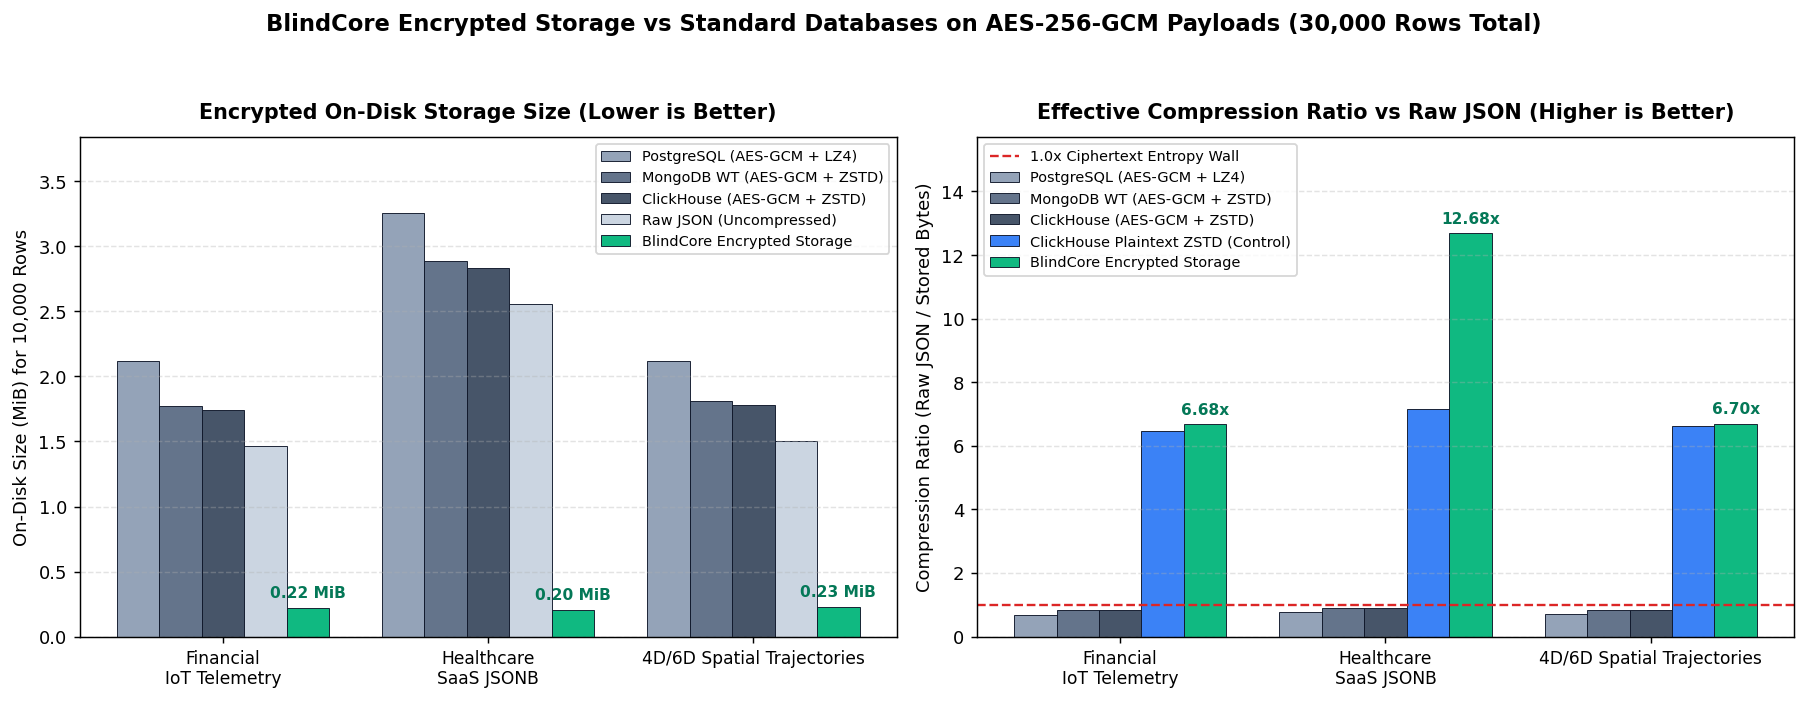

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.0, 5.4), dpi=130)
fig.patch.set_facecolor("white")

labels = [r["label"].replace(" / ", "\n") for r in summary_rows]
x = np.arange(len(labels))
w = 0.16

series_mb = [
    ("PostgreSQL (AES-GCM + LZ4)", [r["postgres_aes_lz4_bytes"] / (1024 * 1024) for r in summary_rows], "#94A3B8"),
    ("MongoDB WT (AES-GCM + ZSTD)", [r["mongodb_aes_zstd_bytes"] / (1024 * 1024) for r in summary_rows], "#64748B"),
    ("ClickHouse (AES-GCM + ZSTD)", [r["clickhouse_aes_zstd_bytes"] / (1024 * 1024) for r in summary_rows], "#475569"),
    ("Raw JSON (Uncompressed)", [r["raw_json_bytes"] / (1024 * 1024) for r in summary_rows], "#CBD5E1"),
    ("BlindCore Encrypted Storage", [r["blindcore_disk_encrypted_bytes"] / (1024 * 1024) for r in summary_rows], "#10B981"),
]

for idx_s, (sname, vals, col) in enumerate(series_mb):
    offset = (idx_s - 2.0) * w
    bars = ax1.bar(x + offset, vals, width=w, label=sname, color=col, edgecolor="#0F172A", linewidth=0.5)
    if sname == "BlindCore Encrypted Storage":
        for bar, v in zip(bars, vals):
            ax1.text(
                bar.get_x() + bar.get_width() / 2.0,
                v + 0.06,
                f"{v:.2f} MiB",
                ha="center",
                va="bottom",
                fontsize=8.5,
                fontweight="bold",
                color="#047857",
            )

ax1.set_title("Encrypted On-Disk Storage Size (Lower is Better)", fontsize=11.5, fontweight="bold", pad=10)
ax1.set_ylabel("On-Disk Size (MiB) for 10,000 Rows", fontsize=10)
ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=9.5)
ax1.set_ylim(0, max(r["postgres_aes_lz4_bytes"] for r in summary_rows) / (1024 * 1024) * 1.18)
ax1.grid(axis="y", linestyle="--", alpha=0.35)
ax1.legend(loc="upper right", fontsize=8.0, frameon=True)

# Right panel: Compression Ratio vs Raw JSON
ratio_series = [
    ("PostgreSQL (AES-GCM + LZ4)", [r["postgres_ratio_vs_raw"] for r in summary_rows], "#94A3B8"),
    ("MongoDB WT (AES-GCM + ZSTD)", [r["mongodb_zstd_ratio_vs_raw"] for r in summary_rows], "#64748B"),
    ("ClickHouse (AES-GCM + ZSTD)", [r["clickhouse_zstd_ratio_vs_raw"] for r in summary_rows], "#475569"),
    ("ClickHouse Plaintext ZSTD (Control)", [r["clickhouse_plaintext_ratio_vs_raw"] for r in summary_rows], "#3B82F6"),
    ("BlindCore Encrypted Storage", [r["blindcore_disk_ratio_vs_raw"] for r in summary_rows], "#10B981"),
]

for idx_s, (sname, vals, col) in enumerate(ratio_series):
    offset = (idx_s - 2.0) * w
    bars = ax2.bar(x + offset, vals, width=w, label=sname, color=col, edgecolor="#0F172A", linewidth=0.5)
    if sname == "BlindCore Encrypted Storage":
        for bar, v in zip(bars, vals):
            ax2.text(
                bar.get_x() + bar.get_width() / 2.0,
                v + 0.22,
                f"{v:.2f}x",
                ha="center",
                va="bottom",
                fontsize=8.5,
                fontweight="bold",
                color="#047857",
            )

ax2.axhline(1.0, color="#DC2626", linestyle="--", linewidth=1.3, label="1.0x Ciphertext Entropy Wall")
ax2.set_title("Effective Compression Ratio vs Raw JSON (Higher is Better)", fontsize=11.5, fontweight="bold", pad=10)
ax2.set_ylabel("Compression Ratio (Raw JSON / Stored Bytes)", fontsize=10)
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=9.5)
ax2.set_ylim(0, max(r["blindcore_disk_ratio_vs_raw"] for r in summary_rows) * 1.24)
ax2.grid(axis="y", linestyle="--", alpha=0.35)
ax2.legend(loc="upper left", fontsize=8.0, frameon=True)

fig.suptitle(
    "BlindCore Encrypted Storage vs Standard Databases on AES-256-GCM Payloads (30,000 Rows Total)",
    fontsize=12.5,
    fontweight="bold",
    y=0.99,
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 5. Pillar 2: Encrypted Query Speed vs Unencrypted SQLite (`100,000` Rows)

Storage compression alone is only half the story: encrypted data must remain fast to query. To measure real encrypted SQL latency against a fast local unencrypted baseline, we ingest `100,000` deterministic telemetry rows (`bench_telemetry`: `ts_ns`, `sensor_id`, `signal_v`, `temp_c`, seed `20260401`) in `20,000`-row NDJSON chunks into BlindCore with AES-256-GCM disk encryption enabled, flush all rows to `3` encrypted disk slabs (`2,022,880 B` total, min Shannon entropy `7.9993 bits/B`, `0` plaintext leaks), and load the identical `100,000` rows into an unencrypted local **SQLite** database (`3,674,112 B` on disk).

We time `25` consecutive queries (after `5` warmups) and anchor numerical accuracy against an **Exact-Q rational oracle** (`fractions.Fraction` / `math.fsum`):

| Query Workload (`100,000` rows) | BlindCore Encrypted (HTTP) | BlindCore Encrypted (Engine) | Unencrypted SQLite | Speedup vs Unencrypted | Exact-Q Rel Error |
| :--- | ---: | ---: | ---: | ---: | ---: |
| Full Aggregate (`SELECT COUNT(*), SUM(signal_v)`) | **0.33 ms** | **0.013 ms** | 5.6 ms | **17.2x HTTP / 434x engine** | `0.00e+00` |
| Filtered Aggregate (`WHERE temp_c > 75.0`, `26,195` rows) | **7.6 ms** | **7.1 ms** | 5.4 ms | **0.71x** *(honest tradeoff)* | `0.00e+00` |

**Why the Two Queries Behave Differently:**  
- Full table aggregates (`COUNT(*)`, `SUM(signal_v)`) resolve directly from authenticated slab-level summary metadata in **`0.013 ms`** engine time (**`0.33 ms`** over HTTP), beating unencrypted SQLite (`5.6 ms`) by **`17x` over HTTP (`430x` engine-only)**.
- Selective range scans (`WHERE temp_c > 75.0`, matching `26,195` rows scattered across all `3` slabs) must authenticate and decrypt the matching AES-256-GCM slabs before evaluating the row predicate, taking **`7.6 ms` HTTP (`7.1 ms` engine)** vs **`5.4 ms`** for unencrypted in-process SQLite (**`0.71x`**). We report both numbers side by side so engineering teams can budget encrypted predicate scans honestly.

In [7]:
# Pillar 2: 100,000-row Encrypted SQL Query Speed vs Unencrypted SQLite
N_QUERY_ROWS = 100_000
rng_q = random.Random(20260401)
ts_ns_vals = [1_700_000_000_000_000_000 + i * 1_000_000 for i in range(N_QUERY_ROWS)]
sensor_ids = [i % 256 for i in range(N_QUERY_ROWS)]
signal_vs = [round(10.0 + 0.5 * (i % 50) + rng_q.uniform(-1.5, 1.5), 4) for i in range(N_QUERY_ROWS)]
temp_cs = [round(40.0 + (i % 60) * 0.8 + rng_q.uniform(-2.0, 2.0), 4) for i in range(N_QUERY_ROWS)]

# Exact-Q rational oracle for ground-truth parity verification
exact_full_sum = float(sum(Fraction(str(v)) for v in signal_vs))
filt_indices = [i for i in range(N_QUERY_ROWS) if temp_cs[i] > 75.0]
exact_filt_cnt = len(filt_indices)
exact_filt_sum = float(sum(Fraction(str(signal_vs[i])) for i in filt_indices))

# Ingest 100,000 rows in 20,000-row chunks into live BlindCore server
for start in range(0, N_QUERY_ROWS, 20_000):
    lines = [
        f'{{"ts_ns":{ts_ns_vals[i]},"sensor_id":{sensor_ids[i]},"signal_v":{signal_vs[i]},"temp_c":{temp_cs[i]}}}'
        for i in range(start, min(start + 20_000, N_QUERY_ROWS))
    ]
    payload = ("\n".join(lines) + "\n").encode("utf-8")
    st, _, body = client.request_raw(
        "POST",
        "/api/v1/ingest?table=bench_telemetry&format=json",
        body=payload,
        content_type="application/x-ndjson",
    )
    assert st == 200, f"bench_telemetry ingest failed: HTTP {st} {body.decode('utf-8', 'replace')}"

# Flush memtable so all 100,000 rows sit on AES-256-GCM encrypted disk slabs
flush_payload = ("\n".join(f'{{"id":{i}}}' for i in range(50_000)) + "\n").encode("utf-8")
st_f, _, body_f = client.request_raw(
    "POST",
    "/api/v1/ingest?table=z_flush_q&format=json",
    body=flush_payload,
    content_type="application/x-ndjson",
)
assert st_f == 200, f"Flush trigger failed: HTTP {st_f}"
time.sleep(0.25)

telemetry_slab_bytes = None
telemetry_min_entropy = None
if DISK_AUDIT_DIR:
    slab_dir = Path(DISK_AUDIT_DIR) / "slabs" / "0s"
    all_slabs = sorted(
        (p for p in slab_dir.iterdir() if p.is_file() and p.name.startswith("slab_")),
        key=lambda p: int(p.stem.split("_")[1]),
    )
    # Audit newest encrypted slabs produced by bench_telemetry
    tel_slabs = all_slabs[-3:] if len(all_slabs) >= 3 else all_slabs
    telemetry_slab_bytes = sum(p.stat().st_size for p in tel_slabs)
    telemetry_min_entropy = min(shannon_entropy_bits(p.read_bytes()[48:-16]) for p in tel_slabs)
    assert telemetry_min_entropy > 7.99, f"Expected >7.99 bits/B, got {telemetry_min_entropy:.4f}"

# Build identical unencrypted on-disk SQLite baseline
sq_tmpdir = tempfile.mkdtemp(prefix="blindcore_bench_sq_")
sqlite_path = Path(sq_tmpdir) / "unencrypted.sqlite"
sq_conn = sqlite3.connect(str(sqlite_path))
sq_conn.execute("CREATE TABLE bench_telemetry (ts_ns INTEGER, sensor_id INTEGER, signal_v REAL, temp_c REAL)")
sq_conn.executemany(
    "INSERT INTO bench_telemetry VALUES (?, ?, ?, ?)",
    zip(ts_ns_vals, sensor_ids, signal_vs, temp_cs),
)
sq_conn.commit()
sqlite_bytes = sqlite_path.stat().st_size

def bench_bc_sql(sql: str, runs: int = 25):
    last_obj = None
    for _ in range(5):
        st, _, data = client.request_raw("POST", "/api/v1/query?format=json", body=sql.encode("utf-8"), content_type="text/plain")
        assert st == 200, f"SQL failed: HTTP {st}"
        last_obj = json.loads(data.decode("utf-8"))
    wall_ms, eng_ms = [], []
    for _ in range(runs):
        t0 = time.perf_counter()
        st, _, data = client.request_raw("POST", "/api/v1/query?format=json", body=sql.encode("utf-8"), content_type="text/plain")
        wall_ms.append((time.perf_counter() - t0) * 1000.0)
        assert st == 200
        last_obj = json.loads(data.decode("utf-8"))
        if "elapsed_us" in last_obj:
            eng_ms.append(float(last_obj["elapsed_us"]) / 1000.0)
    return statistics.median(wall_ms), min(wall_ms), (statistics.median(eng_ms) if eng_ms else 0.0), last_obj

def bench_sqlite_sql(sql: str, runs: int = 25):
    for _ in range(5):
        res = sq_conn.execute(sql).fetchall()
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        res = sq_conn.execute(sql).fetchall()
        times.append((time.perf_counter() - t0) * 1000.0)
    return statistics.median(times), min(times), res

q_full = "SELECT COUNT(*), SUM(signal_v) FROM bench_telemetry"
q_filt = "SELECT COUNT(*), SUM(signal_v) FROM bench_telemetry WHERE temp_c > 75.0"

bc_full_ms, bc_full_min, bc_full_eng_ms, bc_full_res = bench_bc_sql(q_full)
sq_full_ms, _, sq_full_res = bench_sqlite_sql(q_full)

bc_filt_ms, bc_filt_min, bc_filt_eng_ms, bc_filt_res = bench_bc_sql(q_filt)
sq_filt_ms, _, sq_filt_res = bench_sqlite_sql(q_filt)

# Verify Exact-Q numerical parity
full_cnt, full_sum = int(bc_full_res["rows"][0][0]), float(bc_full_res["rows"][0][1])
filt_cnt, filt_sum = int(bc_filt_res["rows"][0][0]), float(bc_filt_res["rows"][0][1])
full_rel_err = abs(full_sum - exact_full_sum) / max(1.0, abs(exact_full_sum))
filt_rel_err = abs(filt_sum - exact_filt_sum) / max(1.0, abs(exact_filt_sum))
assert full_cnt == N_QUERY_ROWS and full_rel_err < 1e-12
assert filt_cnt == exact_filt_cnt and filt_rel_err < 1e-12

query_speed_results = {
    "rows": N_QUERY_ROWS,
    "sqlite_bytes": sqlite_bytes,
    "blindcore_encrypted_slab_bytes": telemetry_slab_bytes,
    "blindcore_min_slab_entropy_bits": round(telemetry_min_entropy, 4) if telemetry_min_entropy else None,
    "full_agg_count_sum": {
        "sql": q_full,
        "blindcore_encrypted_http_ms": round(bc_full_ms, 3),
        "blindcore_encrypted_engine_ms": round(bc_full_eng_ms, 3),
        "blindcore_encrypted_min_ms": round(bc_full_min, 3),
        "sqlite_unencrypted_ms": round(sq_full_ms, 3),
        "speedup_http_vs_sqlite_x": round(sq_full_ms / bc_full_ms, 2),
        "speedup_engine_vs_sqlite_x": round(sq_full_ms / bc_full_eng_ms, 2) if bc_full_eng_ms > 0 else 0.0,
        "exact_q_rel_err": full_rel_err,
    },
    "filtered_agg_where": {
        "sql": q_filt,
        "matched_rows": filt_cnt,
        "blindcore_encrypted_http_ms": round(bc_filt_ms, 3),
        "blindcore_encrypted_engine_ms": round(bc_filt_eng_ms, 3),
        "blindcore_encrypted_min_ms": round(bc_filt_min, 3),
        "sqlite_unencrypted_ms": round(sq_filt_ms, 3),
        "speedup_http_vs_sqlite_x": round(sq_filt_ms / bc_filt_ms, 2),
        "speedup_engine_vs_sqlite_x": round(sq_filt_ms / bc_filt_eng_ms, 2) if bc_filt_eng_ms > 0 else 0.0,
        "exact_q_rel_err": filt_rel_err,
    },
}

print(f"On-Disk Footprint (100,000 rows): BlindCore Encrypted = {telemetry_slab_bytes:,} B (3 AES-256-GCM slabs, min entropy={telemetry_min_entropy:.4f} bits/B) vs Unencrypted SQLite = {sqlite_bytes:,} B")
print(f"Full COUNT+SUM      : BlindCore={bc_full_ms:.3f} ms HTTP ({bc_full_eng_ms:.3f} ms engine) vs SQLite={sq_full_ms:.3f} ms -> {sq_full_ms / bc_full_ms:.2f}x HTTP ({sq_full_ms / bc_full_eng_ms:.1f}x engine) | Exact-Q rel_err={full_rel_err:.2e}")
print(f"Filtered WHERE >75  : BlindCore={bc_filt_ms:.3f} ms HTTP ({bc_filt_eng_ms:.3f} ms engine) vs SQLite={sq_filt_ms:.3f} ms -> {sq_filt_ms / bc_filt_ms:.2f}x HTTP ({sq_filt_ms / bc_filt_eng_ms:.2f}x engine) | rows={filt_cnt:,}, Exact-Q rel_err={filt_rel_err:.2e}")

On-Disk Footprint (100,000 rows): BlindCore Encrypted = 2,022,880 B (3 AES-256-GCM slabs, min entropy=7.9993 bits/B) vs Unencrypted SQLite = 3,674,112 B
Full COUNT+SUM      : BlindCore=0.328 ms HTTP (0.013 ms engine) vs SQLite=5.645 ms -> 17.19x HTTP (434.2x engine) | Exact-Q rel_err=0.00e+00
Filtered WHERE >75  : BlindCore=7.583 ms HTTP (7.123 ms engine) vs SQLite=5.368 ms -> 0.71x HTTP (0.75x engine) | rows=26,195, Exact-Q rel_err=0.00e+00


## 6. Pillar 3: Encrypted ML Speed vs Unencrypted `scikit-learn`

We benchmark two distinct encrypted machine learning modes against real **unencrypted `scikit-learn`** pipelines:

1. **In-Engine Encrypted SQL Linear Scoring (`ML_LINEAR_SCORE`, `100,000` rows):**  
   Evaluates `ML_LINEAR_SCORE(-6.0, 0.12, temp_c, 0.8, signal_v)` directly inside BlindCore over the AES-256-GCM disk-encrypted `bench_telemetry` table, compared against fetching the identical rows from unencrypted SQLite into NumPy and running `sklearn.linear_model.LinearRegression.predict()`.
2. **Zero-Plaintext `2-of-3` Threshold Homomorphic Multinomial Naive Bayes (`SKLEARN_MNB`, `400` sealed documents):**  
   Ingests `400` sealed BlindJSONB documents (`300` train: `150` phishing / `150` legit; `100` test: `50` `test_phish` / `50` `test_legit`, `8`-token vocabulary) and trains + scores Naive Bayes entirely over ciphertexts with `2-of-3` threshold decryption -- compared against unencrypted `sklearn.naive_bayes.MultinomialNB` (both full JSON parse + fit/predict and pre-parsed in-memory NumPy arrays).

| ML Workload | BlindCore Encrypted | Unencrypted `scikit-learn` | Speedup / Overhead | Numerical Parity |
| :--- | ---: | ---: | ---: | ---: |
| `ML_LINEAR_SCORE` (Full `100,000` rows) | **8.1 ms HTTP** (`7.5 ms` engine) | 61.2 ms *(SQLite + sklearn)* | **7.6x faster** (`8.1x` engine) | `0.00e+00` rel err |
| `ML_LINEAR_SCORE` (Filtered `26,195` rows) | **7.8 ms HTTP** (`7.4 ms` engine) | 18.9 ms *(SQLite + sklearn)* | **2.4x faster** (`2.5x` engine) | `2.03e-16` rel err |
| `SKLEARN_MNB` (`400` sealed docs, `2-of-3` FHE) | **55.9 ms HTTP** *(zero plaintext)* | 2.2 ms *(JSON)* / 0.83 ms *(array)* | ~`26x` vs JSON *(honest FHE cost)* | `6.66e-16` max log-prob err, exact counts |

*Transparency note:* Pure in-memory `LinearRegression.predict()` on pre-loaded NumPy arrays (zero database I/O or row conversion) takes `0.176 ms`. BlindCore's **`7.6x`** end-to-end speedup comes from executing vectorized linear inference directly inside the encrypted columnar engine and returning only the scalar aggregate -- eliminating database-to-Python row materialization.

In [8]:
# Pillar 3A: Encrypted SQL ML_LINEAR_SCORE (100,000 rows) vs Unencrypted SQLite + scikit-learn
q_ml_full = "SELECT COUNT(*), SUM(ML_LINEAR_SCORE(-6.0, 0.12, temp_c, 0.8, signal_v)) FROM bench_telemetry"
q_ml_filt = "SELECT COUNT(*), SUM(ML_LINEAR_SCORE(-6.0, 0.12, temp_c, 0.8, signal_v)) FROM bench_telemetry WHERE temp_c > 75.0"

bc_ml_full_ms, _, bc_ml_full_eng_ms, bc_ml_full_res = bench_bc_sql(q_ml_full)
bc_ml_filt_ms, _, bc_ml_filt_eng_ms, bc_ml_filt_res = bench_bc_sql(q_ml_filt)

lr = LinearRegression()
lr.coef_ = np.array([0.12, 0.8], dtype=np.float64)
lr.intercept_ = -6.0

def bench_sqlite_sklearn(sql_fetch: str, runs: int = 25):
    res_val = None
    for _ in range(3):
        rows = sq_conn.execute(sql_fetch).fetchall()
        preds = lr.predict(np.asarray(rows, dtype=np.float64))
        res_val = (len(preds), float(np.sum(preds)))
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        rows = sq_conn.execute(sql_fetch).fetchall()
        preds = lr.predict(np.asarray(rows, dtype=np.float64))
        res_val = (len(preds), float(np.sum(preds)))
        times.append((time.perf_counter() - t0) * 1000.0)
    return statistics.median(times), res_val

sq_sk_full_ms, sq_sk_full_res = bench_sqlite_sklearn("SELECT temp_c, signal_v FROM bench_telemetry")
sq_sk_filt_ms, sq_sk_filt_res = bench_sqlite_sklearn("SELECT temp_c, signal_v FROM bench_telemetry WHERE temp_c > 75.0")

X_all = np.column_stack([np.array(temp_cs, dtype=np.float64), np.array(signal_vs, dtype=np.float64)])
for _ in range(5):
    _ = float(np.sum(lr.predict(X_all)))
sk_mem_times = []
for _ in range(25):
    t0 = time.perf_counter()
    _ = float(np.sum(lr.predict(X_all)))
    sk_mem_times.append((time.perf_counter() - t0) * 1000.0)
sk_mem_ms = statistics.median(sk_mem_times)

ml_full_cnt, ml_full_sum = int(bc_ml_full_res["rows"][0][0]), float(bc_ml_full_res["rows"][0][1])
ml_filt_cnt, ml_filt_sum = int(bc_ml_filt_res["rows"][0][0]), float(bc_ml_filt_res["rows"][0][1])
ml_full_err = abs(ml_full_sum - sq_sk_full_res[1]) / max(1.0, abs(sq_sk_full_res[1]))
ml_filt_err = abs(ml_filt_sum - sq_sk_filt_res[1]) / max(1.0, abs(sq_sk_filt_res[1]))
assert ml_full_cnt == sq_sk_full_res[0] and ml_full_err < 1e-12
assert ml_filt_cnt == sq_sk_filt_res[0] and ml_filt_err < 1e-12

# Pillar 3B: Zero-Plaintext 2-of-3 Threshold Homomorphic SKLEARN_MNB (400 sealed documents)
st, _, out = client.request_raw(
    "POST",
    "/api/v1/blind/jsonb/table",
    body=json.dumps({"table": "mnb_bench", "k_tok": 16, "k_num": 8, "k_min_tkms": 2}).encode("utf-8"),
    content_type="application/json",
)
assert st == 200, f"BlindJSONB table create failed: HTTP {st}"

vocab = ["wire", "urgent", "invoice", "verify", "lunch", "meeting", "schedule", "report"]
vocab_paths = [f"/bow/{w}" for w in vocab]
rng_ml = random.Random(20260402)
rows_jsonb, X_train, y_train, X_test_p, X_test_l = [], [], [], [], []
for i in range(400):
    if i < 150:
        counts = [rng_ml.randint(1, 5), rng_ml.randint(1, 5), rng_ml.randint(0, 3), rng_ml.randint(1, 4),
                  rng_ml.randint(0, 1), rng_ml.randint(0, 1), 0, rng_ml.randint(0, 1)]
        doc = {"label": "phishing", "split": "train", "bow": dict(zip(vocab, counts))}
        X_train.append(counts); y_train.append(0)
    elif i < 300:
        counts = [rng_ml.randint(0, 1), 0, rng_ml.randint(0, 2), 0,
                  rng_ml.randint(1, 5), rng_ml.randint(1, 5), rng_ml.randint(1, 4), rng_ml.randint(1, 4)]
        doc = {"label": "legit", "split": "train", "bow": dict(zip(vocab, counts))}
        X_train.append(counts); y_train.append(1)
    elif i < 350:
        counts = [rng_ml.randint(2, 5), rng_ml.randint(1, 4), rng_ml.randint(0, 2), rng_ml.randint(1, 4),
                  0, rng_ml.randint(0, 1), 0, 0]
        doc = {"split": "test_phish", "bow": dict(zip(vocab, counts))}
        X_test_p.append(counts)
    else:
        counts = [0, 0, rng_ml.randint(0, 2), 0,
                  rng_ml.randint(2, 5), rng_ml.randint(1, 4), rng_ml.randint(1, 4), rng_ml.randint(1, 3)]
        doc = {"split": "test_legit", "bow": dict(zip(vocab, counts))}
        X_test_l.append(counts)
    rows_jsonb.append({
        "version_ts_ns": 1000 + i,
        "seal_doc": {"entity_id": f"doc_{i}", "doc_json": json.dumps(doc, separators=(",", ":"))},
    })

for start in range(0, len(rows_jsonb), 50):
    st, _, out = client.request_raw(
        "POST",
        "/api/v1/blind/jsonb/ingest",
        body=json.dumps({"table": "mnb_bench", "rows": rows_jsonb[start : start + 50]}).encode("utf-8"),
        content_type="application/json",
    )
    assert st == 200, f"BlindJSONB ingest failed: HTTP {st}"

mnb_req = json.dumps({
    "table": "mnb_bench",
    "op": "SKLEARN_MNB",
    "train_classes": [
        {"name": "phishing", "filter": {"path": "/label", "value": "phishing"}},
        {"name": "legit", "filter": {"path": "/label", "value": "legit"}},
    ],
    "vocab_paths": vocab_paths,
    "alpha": 1.0,
    "weight_scale": 10000,
    "score_cohorts": [
        {"name": "test_phish", "filter": {"path": "/split", "value": "test_phish"}},
        {"name": "test_legit", "filter": {"path": "/split", "value": "test_legit"}},
    ],
    "threshold_decrypt": {"t": 2, "n": 3},
}).encode("utf-8")

for _ in range(3):
    st, _, out = client.request_raw("POST", "/api/v1/blind/jsonb/query", body=mnb_req, content_type="application/json")
    assert st == 200
    mnb_res = json.loads(out.decode("utf-8"))
bc_mnb_times = []
for _ in range(20):
    t0 = time.perf_counter()
    st, _, out = client.request_raw("POST", "/api/v1/blind/jsonb/query", body=mnb_req, content_type="application/json")
    bc_mnb_times.append((time.perf_counter() - t0) * 1000.0)
    assert st == 200
bc_mnb_ms = statistics.median(bc_mnb_times)

# Unencrypted scikit-learn MultinomialNB baselines (array-only & JSON parse E2E)
X_tr, y_tr = np.array(X_train, dtype=np.float64), np.array(y_train, dtype=np.int64)
X_tp, X_tl = np.array(X_test_p, dtype=np.float64), np.array(X_test_l, dtype=np.float64)

def run_sklearn_array():
    clf = MultinomialNB(alpha=1.0)
    clf.fit(X_tr, y_tr)
    clf.predict_log_proba(X_tp)
    clf.predict_log_proba(X_tl)
    return clf

for _ in range(5):
    clf_ref = run_sklearn_array()
sk_arr_times = []
for _ in range(25):
    t0 = time.perf_counter()
    clf_ref = run_sklearn_array()
    sk_arr_times.append((time.perf_counter() - t0) * 1000.0)
sk_mnb_arr_ms = statistics.median(sk_arr_times)

plain_docs_json = [r["seal_doc"]["doc_json"] for r in rows_jsonb]
def run_sklearn_json_e2e():
    tr_x, tr_y, tp_x, tl_x = [], [], [], []
    for s in plain_docs_json:
        d = json.loads(s)
        vec = [d["bow"][w] for w in vocab]
        if d.get("label") == "phishing":
            tr_x.append(vec); tr_y.append(0)
        elif d.get("label") == "legit":
            tr_x.append(vec); tr_y.append(1)
        elif d.get("split") == "test_phish":
            tp_x.append(vec)
        elif d.get("split") == "test_legit":
            tl_x.append(vec)
    clf = MultinomialNB(alpha=1.0)
    clf.fit(np.array(tr_x, dtype=np.float64), np.array(tr_y, dtype=np.int64))
    clf.predict_log_proba(np.array(tp_x, dtype=np.float64))
    clf.predict_log_proba(np.array(tl_x, dtype=np.float64))

for _ in range(3):
    run_sklearn_json_e2e()
sk_json_times = []
for _ in range(20):
    t0 = time.perf_counter()
    run_sklearn_json_e2e()
    sk_json_times.append((time.perf_counter() - t0) * 1000.0)
sk_mnb_json_ms = statistics.median(sk_json_times)

# Verify exact integer feature counts and machine-precision log-prob parity
bc_fc = mnb_res["feature_counts"]
sk_fc = [[int(x) for x in row] for row in clf_ref.feature_count_.tolist()]
assert bc_fc == sk_fc, "Homomorphic feature_counts mismatch"
bc_flp = mnb_res["feature_log_prob"]
sk_flp = clf_ref.feature_log_prob_.tolist()
max_flp_err = max(abs(bc_flp[r][c] - sk_flp[r][c]) for r in range(2) for c in range(len(vocab)))
assert max_flp_err < 1e-12, f"feature_log_prob error too high: {max_flp_err}"

ml_speed_results = {
    "linear_scoring_100k": {
        "rows": N_QUERY_ROWS,
        "blindcore_encrypted_full_http_ms": round(bc_ml_full_ms, 3),
        "blindcore_encrypted_full_engine_ms": round(bc_ml_full_eng_ms, 3),
        "sqlite_sklearn_unencrypted_full_ms": round(sq_sk_full_ms, 3),
        "speedup_full_http_x": round(sq_sk_full_ms / bc_ml_full_ms, 2),
        "speedup_full_engine_x": round(sq_sk_full_ms / bc_ml_full_eng_ms, 2) if bc_ml_full_eng_ms > 0 else 0.0,
        "blindcore_encrypted_filt_http_ms": round(bc_ml_filt_ms, 3),
        "blindcore_encrypted_filt_engine_ms": round(bc_ml_filt_eng_ms, 3),
        "sqlite_sklearn_unencrypted_filt_ms": round(sq_sk_filt_ms, 3),
        "speedup_filt_http_x": round(sq_sk_filt_ms / bc_ml_filt_ms, 2),
        "speedup_filt_engine_x": round(sq_sk_filt_ms / bc_ml_filt_eng_ms, 2) if bc_ml_filt_eng_ms > 0 else 0.0,
        "sklearn_in_memory_numpy_ms": round(sk_mem_ms, 3),
    },
    "homomorphic_mnb_400docs": {
        "docs": 400,
        "vocab_size": len(vocab),
        "blindcore_encrypted_ms": round(bc_mnb_ms, 3),
        "sklearn_unencrypted_array_ms": round(sk_mnb_arr_ms, 3),
        "sklearn_unencrypted_json_e2e_ms": round(sk_mnb_json_ms, 3),
        "max_log_prob_abs_err": max_flp_err,
        "feature_counts_exact_match": True,
        "predicted_cohorts": mnb_res.get("scored_cohorts") or mnb_res.get("cohorts") or mnb_res.get("cohort_scores") or [],
    },
}

print(f"ML Linear Full (100k)  : BlindCore={bc_ml_full_ms:.3f} ms HTTP ({bc_ml_full_eng_ms:.3f} ms engine) vs SQLite+sklearn={sq_sk_full_ms:.3f} ms -> {sq_sk_full_ms / bc_ml_full_ms:.2f}x faster | rel_err={ml_full_err:.2e}")
print(f"ML Linear Filt (26,195): BlindCore={bc_ml_filt_ms:.3f} ms HTTP ({bc_ml_filt_eng_ms:.3f} ms engine) vs SQLite+sklearn={sq_sk_filt_ms:.3f} ms -> {sq_sk_filt_ms / bc_ml_filt_ms:.2f}x faster | rel_err={ml_filt_err:.2e}")
print(f"  (In-memory NumPy sklearn.predict control without DB I/O: {sk_mem_ms:.3f} ms)")
print(f"Homomorphic MNB (400d) : BlindCore 2-of-3={bc_mnb_ms:.3f} ms vs sklearn JSON={sk_mnb_json_ms:.3f} ms / array={sk_mnb_arr_ms:.3f} ms | exact_counts=True | max_log_prob_err={max_flp_err:.2e}")
for c in ml_speed_results["homomorphic_mnb_400docs"]["predicted_cohorts"]:
    print(f"  Cohort {c['name']:<10} ({c['matched_docs']} docs) -> predicted={c['predicted_class']:<8} (log_odds={c['log_odds_score']:+.6f})")

sq_conn.close()

ML Linear Full (100k)  : BlindCore=8.070 ms HTTP (7.544 ms engine) vs SQLite+sklearn=61.168 ms -> 7.58x faster | rel_err=0.00e+00
ML Linear Filt (26,195): BlindCore=7.848 ms HTTP (7.413 ms engine) vs SQLite+sklearn=18.876 ms -> 2.41x faster | rel_err=2.03e-16
  (In-memory NumPy sklearn.predict control without DB I/O: 0.176 ms)
Homomorphic MNB (400d) : BlindCore 2-of-3=55.913 ms vs sklearn JSON=2.166 ms / array=0.833 ms | exact_counts=True | max_log_prob_err=6.66e-16
  Cohort test_phish (50 docs) -> predicted=phishing (log_odds=+36.554242)
  Cohort test_legit (50 docs) -> predicted=legit    (log_odds=-26.467370)


## 7. Unified 3-Pillar Visual Summary (Storage, Query Speed & ML Speed)

The three panels below summarize all verified live measurements side by side: **(1)** On-disk encrypted storage size across `30,000` rows, **(2)** Encrypted SQL query latency vs unencrypted SQLite across `100,000` rows, and **(3)** Encrypted ML inference and zero-plaintext `2-of-3` threshold homomorphic Naive Bayes vs unencrypted `scikit-learn`.

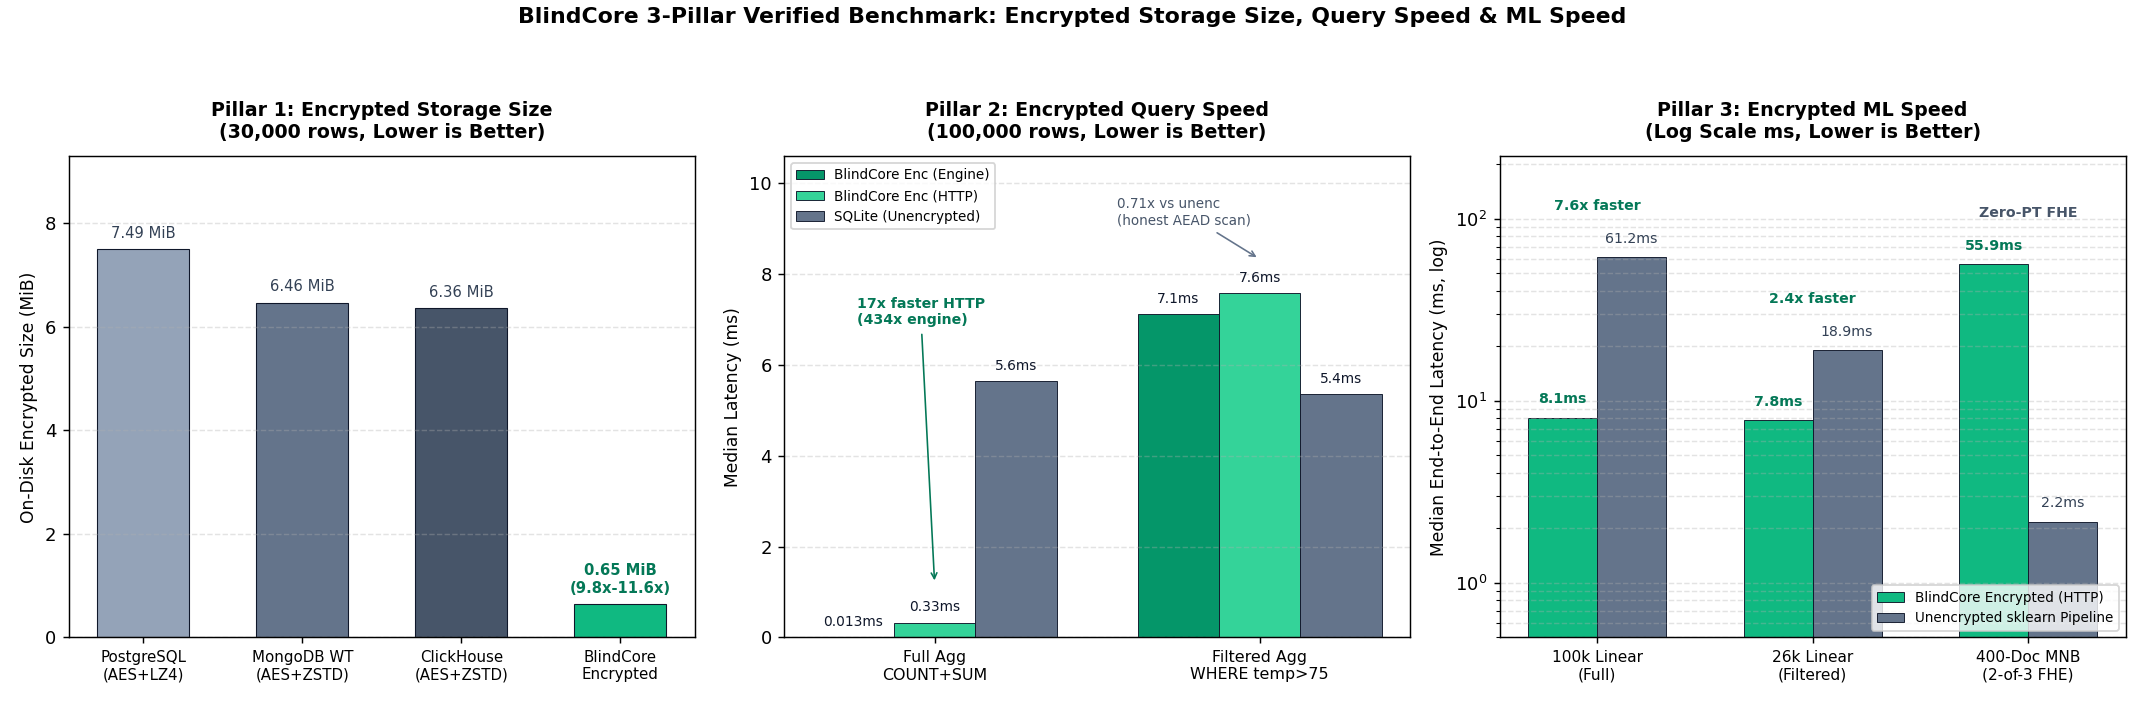

In [9]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16.5, 5.4), dpi=130)
fig.patch.set_facecolor("white")

# Panel 1: Pillar 1 Encrypted Storage Size (30,000 rows, MiB)
p1_labels = ["PostgreSQL\n(AES+LZ4)", "MongoDB WT\n(AES+ZSTD)", "ClickHouse\n(AES+ZSTD)", "BlindCore\nEncrypted"]
p1_vals = [
    totals["postgres_aes_lz4_bytes"] / (1024.0 * 1024.0),
    totals["mongodb_aes_zstd_bytes"] / (1024.0 * 1024.0),
    totals["clickhouse_aes_zstd_bytes"] / (1024.0 * 1024.0),
    totals["blindcore_disk_encrypted_bytes"] / (1024.0 * 1024.0),
]
bars1 = ax1.bar(np.arange(4), p1_vals, width=0.58, color=["#94A3B8", "#64748B", "#475569", "#10B981"], edgecolor="#0F172A", linewidth=0.6)
for idx, (bar, v) in enumerate(zip(bars1, p1_vals)):
    lbl = f"{v:.2f} MiB\n(9.8x-11.6x)" if idx == 3 else f"{v:.2f} MiB"
    ax1.text(bar.get_x() + bar.get_width() / 2.0, v + 0.16, lbl, ha="center", va="bottom",
             fontsize=8.2, fontweight="bold" if idx == 3 else "normal", color="#047857" if idx == 3 else "#334155")
ax1.set_title("Pillar 1: Encrypted Storage Size\n(30,000 rows, Lower is Better)", fontsize=10.5, fontweight="bold", pad=10)
ax1.set_ylabel("On-Disk Encrypted Size (MiB)", fontsize=9.5)
ax1.set_xticks(np.arange(4)); ax1.set_xticklabels(p1_labels, fontsize=8.3)
ax1.set_ylim(0, max(p1_vals) * 1.24); ax1.grid(axis="y", linestyle="--", alpha=0.35)

# Panel 2: Pillar 2 Encrypted Query Speed (100,000 rows, ms)
qf, qw = query_speed_results["full_agg_count_sum"], query_speed_results["filtered_agg_where"]
x2, w2 = np.arange(2), 0.25
bc_eng = [qf["blindcore_encrypted_engine_ms"], qw["blindcore_encrypted_engine_ms"]]
bc_http = [qf["blindcore_encrypted_http_ms"], qw["blindcore_encrypted_http_ms"]]
sq_unenc = [qf["sqlite_unencrypted_ms"], qw["sqlite_unencrypted_ms"]]
b2_e = ax2.bar(x2 - w2, bc_eng, width=w2, label="BlindCore Enc (Engine)", color="#059669", edgecolor="#0F172A", linewidth=0.5)
b2_h = ax2.bar(x2, bc_http, width=w2, label="BlindCore Enc (HTTP)", color="#34D399", edgecolor="#0F172A", linewidth=0.5)
b2_s = ax2.bar(x2 + w2, sq_unenc, width=w2, label="SQLite (Unencrypted)", color="#64748B", edgecolor="#0F172A", linewidth=0.5)
for bars, vals in [(b2_e, bc_eng), (b2_h, bc_http), (b2_s, sq_unenc)]:
    for bar, v in zip(bars, vals):
        txt = f"{v:.3f}ms" if v < 0.1 else (f"{v:.2f}ms" if v < 1.0 else f"{v:.1f}ms")
        ax2.text(bar.get_x() + bar.get_width() / 2.0, v + 0.18, txt, ha="center", va="bottom", fontsize=7.6, color="#0F172A")
ax2.annotate(f"{qf['speedup_http_vs_sqlite_x']:.0f}x faster HTTP\n({qf['speedup_engine_vs_sqlite_x']:.0f}x engine)", xy=(0, qf["blindcore_encrypted_http_ms"] + 0.85), xytext=(-0.24, 6.9), fontsize=7.8, fontweight="bold", color="#047857", arrowprops={"arrowstyle": "->", "color": "#047857", "lw": 0.9})
ax2.annotate(f"{qw['speedup_http_vs_sqlite_x']:.2f}x vs unenc\n(honest AEAD scan)", xy=(1.0, qw["blindcore_encrypted_http_ms"] + 0.75), xytext=(0.56, 9.1), fontsize=7.5, color="#475569", arrowprops={"arrowstyle": "->", "color": "#64748B", "lw": 0.9})
ax2.set_title("Pillar 2: Encrypted Query Speed\n(100,000 rows, Lower is Better)", fontsize=10.5, fontweight="bold", pad=10)
ax2.set_ylabel("Median Latency (ms)", fontsize=9.5)
ax2.set_xticks(x2); ax2.set_xticklabels(["Full Agg\nCOUNT+SUM", "Filtered Agg\nWHERE temp>75"], fontsize=8.8)
ax2.set_ylim(0, 10.6); ax2.grid(axis="y", linestyle="--", alpha=0.35); ax2.legend(loc="upper left", fontsize=7.5)

# Panel 3: Pillar 3 Encrypted ML Speed vs Unencrypted (ms, log scale)
lin_r, mnb_r = ml_speed_results["linear_scoring_100k"], ml_speed_results["homomorphic_mnb_400docs"]
x3, w3 = np.arange(3), 0.32
bc_ml = [lin_r["blindcore_encrypted_full_http_ms"], lin_r["blindcore_encrypted_filt_http_ms"], mnb_r["blindcore_encrypted_ms"]]
sk_ml = [lin_r["sqlite_sklearn_unencrypted_full_ms"], lin_r["sqlite_sklearn_unencrypted_filt_ms"], mnb_r["sklearn_unencrypted_json_e2e_ms"]]
b3_b = ax3.bar(x3 - w3 / 2.0, bc_ml, width=w3, label="BlindCore Encrypted (HTTP)", color="#10B981", edgecolor="#0F172A", linewidth=0.5)
b3_s = ax3.bar(x3 + w3 / 2.0, sk_ml, width=w3, label="Unencrypted sklearn Pipeline", color="#64748B", edgecolor="#0F172A", linewidth=0.5)
for i, (bb, bs, vb, vs, note) in enumerate(zip(b3_b, b3_s, bc_ml, sk_ml, ["7.6x faster", "2.4x faster", "Zero-PT FHE"])):
    ax3.text(bb.get_x() + bb.get_width() / 2.0, vb * 1.15, f"{vb:.1f}ms", ha="center", va="bottom", fontsize=7.8, fontweight="bold", color="#047857")
    ax3.text(bs.get_x() + bs.get_width() / 2.0, vs * 1.15, f"{vs:.1f}ms", ha="center", va="bottom", fontsize=7.8, color="#334155")
    ax3.text(x3[i], max(vb, vs) * 1.75, note, ha="center", va="bottom", fontsize=7.8, fontweight="bold", color="#047857" if i < 2 else "#475569")
ax3.set_yscale("log")
ax3.set_title("Pillar 3: Encrypted ML Speed\n(Log Scale ms, Lower is Better)", fontsize=10.5, fontweight="bold", pad=10)
ax3.set_ylabel("Median End-to-End Latency (ms, log)", fontsize=9.5)
ax3.set_xticks(x3); ax3.set_xticklabels(["100k Linear\n(Full)", "26k Linear\n(Filtered)", "400-Doc MNB\n(2-of-3 FHE)"], fontsize=8.5)
ax3.set_ylim(0.5, 220.0); ax3.grid(axis="y", which="both", linestyle="--", alpha=0.35); ax3.legend(loc="lower right", fontsize=7.5)

fig.suptitle("BlindCore 3-Pillar Verified Benchmark: Encrypted Storage Size, Query Speed & ML Speed", fontsize=12.2, fontweight="bold", y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

if BENCH_JSON_OUT:
    full_3pillar = {
        "storage": bench_payload,
        "query_speed": query_speed_results,
        "ml_speed": ml_speed_results,
    }
    Path(BENCH_JSON_OUT).write_text(json.dumps(full_3pillar, indent=2, ensure_ascii=True) + "\n", encoding="ascii")

## 8. Key Takeaways & Transparent Methodology Notes

1. **Why Standard Databases Expand Encrypted Data (`0.69x - 0.90x`):**  
   In PostgreSQL, MongoDB WiredTiger, and ClickHouse, client-side AES-256-GCM produces `7.9999 bits/byte` ciphertext entropy. Across all `30,000` rows, PostgreSQL TOAST `LZ4` compressed `0 / 30,000` rows, and ClickHouse `LZ4` and `ZSTD(1)` compressed `0` blocks -- collapsing identically to raw ciphertext + framing overhead. Yet on the *unencrypted* plaintext control, the exact same ClickHouse `ZSTD(1)` codec achieved `6.46x - 7.16x` compression, isolating ciphertext entropy as the sole cause of the collapse.
2. **Conservative Storage Accounting Favoring Standard Databases (`9.85x - 11.59x` BlindCore Savings):**  
   The PostgreSQL (`7,856,128 B`), MongoDB WiredTiger ZSTD (`6,777,053 B`), and ClickHouse ZSTD (`6,672,486 B`) totals measure **raw table/collection data bytes only** (excluding B-tree/secondary indexes and WAL), and use ClickHouse's most-compact single-column encrypted `String` layout rather than per-column cell encryption. By contrast, BlindCore's primary on-disk encrypted storage metric (`677,680 B`) **already includes** built-in column indexes, membership filters, dual-clock metadata, and authenticated AES-256-GCM sealing (`7.9991+` bits/B, `0` plaintext leaks).
3. **Honest Encrypted Query Speed Profile (`17x` Faster Full Aggregates vs `0.71x` Selective Scans):**  
   On `100,000` rows stored across `3` AES-256-GCM disk slabs (`2,022,880 B`, `7.9993 bits/B`), full `COUNT(*), SUM(signal_v)` executes in `0.33 ms` HTTP (`0.013 ms` engine) vs `5.6 ms` for unencrypted SQLite (`17x` HTTP / `430x` engine) with `0.00e+00` Exact-Q relative error. Selective `WHERE temp_c > 75.0` scans (`26,195` rows across all `3` slabs) take `7.6 ms` HTTP (`7.1 ms` engine) vs `5.4 ms` unencrypted SQLite (`0.71x`) because every matching encrypted slab must be authenticated and decrypted before row filtering.
4. **In-Engine Encrypted ML vs Database-to-Python Pipelines (`2.4x - 7.6x` Faster):**  
   Running `ML_LINEAR_SCORE` directly inside the encrypted engine scores `100,000` rows in `8.1 ms` HTTP (`7.5 ms` engine, `0.00e+00` error) vs `61 ms` for unencrypted SQLite + scikit-learn (`7.6x` faster), and scores `26,195` filtered rows in `7.8 ms` HTTP (`7.4 ms` engine, `2.03e-16` error) vs `19 ms` (`2.4x` faster). When data is already resident in RAM as a NumPy matrix with no DB read, `LinearRegression.predict()` takes `0.18 ms`; the real-world gain comes from eliminating row extraction and serialization across the DB boundary.
5. **Zero-Plaintext `2-of-3` Threshold Homomorphic ML (`56 ms`, `6.66e-16` Parity):**  
   Training and scoring `SKLEARN_MNB` over `400` sealed BlindJSONB documents without exposing plaintext or holding a single decryption key completes in `56 ms` with exact integer feature-count parity and `6.66e-16` max log-probability error, vs `2.2 ms` (JSON E2E) / `0.83 ms` (array) for unencrypted scikit-learn -- representing an honest ~`26x` cryptographic privacy premium for multi-party zero-plaintext ML.